# Cheating Tracking & Alert System — YOLOv8s Training

In [1]:
!pip install -q ultralytics roboflow

In [2]:
import os
import yaml
import torch
import shutil
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
from roboflow import Roboflow

print("CUDA Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
CUDA Available: True
GPU: Tesla T4


## 1. Download Dataset from Roboflow

In [3]:
rf = Roboflow(api_key="YOUR_ROBOFLOW_API_KEY")
project = rf.workspace("khangs-workspace-ygoif").project("exam-cheating-l59cc")
version = project.version(3)
dataset = version.download("yolov8")

DATA_DIR = Path(dataset.location)
DATA_YAML = DATA_DIR / "data.yaml"

with open(DATA_YAML, "r") as f:
    cfg = yaml.safe_load(f)

for split, folder in [("train", "train"), ("val", "valid"), ("test", "test")]:
    if (DATA_DIR / folder / "images").exists():
        cfg[split] = str(DATA_DIR / folder / "images")

cfg["path"] = str(DATA_DIR)
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(cfg, f)

print("Dataset:", DATA_DIR)
print("Classes:", cfg["names"])

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to exam-cheating-3 in yolov8:: 100%|██████████| 8371/8371 [00:01<00:00, 6981.49it/s]

Dataset: /content/exam-cheating-3
Classes: ['document', 'earphone', 'exchanging', 'look_around', 'normal_action', 'phone', 'smartwatch', 'using_document', 'using_earphone', 'using_phone', 'using_smartwatch']


## 2. Train YOLOv8s

In [4]:
model = YOLO("yolov8s.pt")
model.train(
    data=str(DATA_YAML),
    epochs=30,
    patience=10,
    imgsz=640,
    batch=16,
    name="cheating_yolov8s",
    exist_ok=True
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/exam-cheating-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=cheating_yolov8s, nbs=64, nms=None, opset=None, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d6d5a400c90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

## 3. Evaluate on Validation / Test Split

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 8.3±4.4 MB/s, size: 48.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/exam-cheating-3/test/labels... 417 images, 46 backgrounds, 2 corrupt: 100% ━━━━━━━━━━━━ 417/417 357.6it/s 1.2s
val: /content/exam-cheating-3/test/images/Su-_du-ng_die-n_thoa-i_199_jpg.rf.4c3fa9f05fa5afde75ffba764b4a31ca.jpg: 1 duplicate labels removed
val: /content/exam-cheating-3/test/images/Su-_du-ng_die-n_thoa-i_61_jpg.rf.579da261230a141e30e1cff5d742f2cd.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/exam-cheating-3/test/images/Su-_du-ng_die-n_thoa-i_61_jpg.rf.a30b2466fcaaf7e91c7f89a09951cfd4.jpg: ignoring corrupt image/label: l

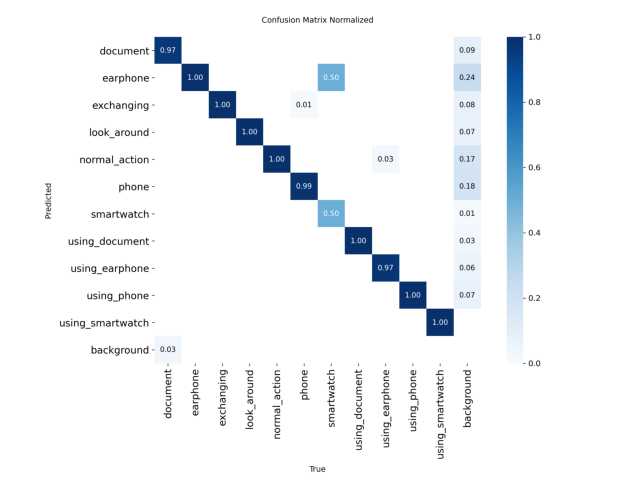

In [5]:
best_weights = "runs/detect/cheating_yolov8s/weights/best.pt"
trained_model = YOLO(best_weights)

eval_split = "test" if "test" in cfg else "val"
metrics = trained_model.val(data=str(DATA_YAML), split=eval_split, imgsz=640, plots=True)

print(f"mAP@50: {metrics.box.map50:.4f}")
print(f"mAP@50-95: {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")

cm_path = Path(metrics.save_dir) / "confusion_matrix_normalized.png"
if cm_path.exists():
    plt.figure(figsize=(8, 8))
    plt.imshow(Image.open(cm_path))
    plt.axis("off")
    plt.show()

## 4. Save & Download best.pt for the Tkinter Desktop App

In [6]:
shutil.copy(best_weights, "best.pt")
print("Saved best.pt — download it and place it next to app.py")

try:
    from google.colab import files
    files.download("best.pt")
except ImportError:
    pass

Saved best.pt — download it and place it next to app.py


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>